In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import uproot

In [2]:
def applyCut(inputDataframe, cut, text=None):
    dataframe = inputDataframe
    nbeforecut = dataframe.shape[0]
    cutDataframe = dataframe.query(cut)
    return cutDataframe

In [3]:
def getData(observables, filename, treename):
    return (uproot.open(filename)[treename]).arrays(observables, library='pd')

In [4]:
def calc_hist(vals, bins=10, weights=None, density=False):
    if weights is None:
        weights = np.ones(vals.shape)
    hist, bins = np.histogram(vals, bins=bins, weights=weights)
    digits = np.digitize(vals, bins)
    errs = np.asarray([np.linalg.norm(weights[digits==i]) for i in range(1, len(bins))])
    if density:
        density_int = weights.sum() * (bins[1] - bins[0])
        hist /= density_int
        errs /= density_int
    return hist, errs, bins

In [5]:
def getRcAndErr(df, ob):
    if (ob == 'b'):
        nos = sum(df[df.b==-1]['w'])
        nss = sum(df[df.b==+1]['w'])
    elif (ob == 'b_ch'):
        nos = sum(df[df.b_ch==-1]['w'])
        nss = sum(df[df.b_ch==+1]['w'])
    elif (ob == 'bs'):
        nos = sum(df[df.bs==-1]['ws'])
        nss = sum(df[df.bs==+1]['ws'])
    else:
        print('Double check the input observable name!')
    rc = (nss-nos)/(nss+nos)
    p = nss/(nss+nos)
    w_array = np.unique(df['w'])
    err2_array = []
    variance_array_test = []
    for i in range(0, len(w_array)):
        if (ob == 'b'):
            p = sum(df[(df.w == w_array[i]) & (df.b==+1)]['w']) / sum(df[df.w == w_array[i]]['w'])
        elif (ob == 'b_ch'):
            p = sum(df[(df.w == w_array[i]) & (df.b_ch==+1)]['w']) / sum(df[df.w == w_array[i]]['w'])            
        elif (ob == 'bs'):
            p = sum(df[(df.w == w_array[i]) & (df.bs==+1)]['w']) / sum(df[df.w == w_array[i]]['ws'])
        else:
            print('Double check the input observable name!')        
        variance = p*(1-p)/df[df.w == w_array[i]].shape[0]
        w = sum(df[df.w == w_array[i]]['w'])/sum(df['w'])
        err2_array.append ( w**2*variance )
    rc_err = 2*np.sqrt(sum(err2_array))
    return rc, rc_err

In [6]:
observables = ['runnumber', 'eventnumber', 'centrality', 'rho', 'jet_pt','jet_eta','jet_phi','jet_area','jet_neutral_fraction',\
               'jet_leading_track_pt','jet_leading_track_charge','jet_leading_track_y','jet_leading_track_phi',\
               'jet_subleading_track_pt','jet_subleading_track_charge','jet_subleading_track_y','jet_subleading_track_phi']

In [7]:
pythia_files = ['/gpfs/gibbs/project/havener/ys668/other_output/rc/isobar/postcut/50pthat1000_pythia_for_BB.root',\
               '/gpfs/gibbs/project/havener/ys668/other_output/rc/isobar/postcut/45pthat50_pythia_for_BB.root',\
               '/gpfs/gibbs/project/havener/ys668/other_output/rc/isobar/postcut/40pthat45_pythia_for_BB.root',\
               '/gpfs/gibbs/project/havener/ys668/other_output/rc/isobar/postcut/35pthat40_pythia_for_BB.root',\
               '/gpfs/gibbs/project/havener/ys668/other_output/rc/isobar/postcut/30pthat35_pythia_for_BB.root',\
               '/gpfs/gibbs/project/havener/ys668/other_output/rc/isobar/postcut/25pthat30_pythia_for_BB.root',\
               '/gpfs/gibbs/project/havener/ys668/other_output/rc/isobar/postcut/20pthat25_pythia_for_BB.root',\
               '/gpfs/gibbs/project/havener/ys668/other_output/rc/isobar/postcut/15pthat20_pythia_for_BB.root',\
               '/gpfs/gibbs/project/havener/ys668/other_output/rc/isobar/postcut/11pthat15_pythia_for_BB.root']
embed_files = ['/gpfs/gibbs/project/havener/ys668/other_output/rc/isobar/postcut/50pthat1000_pythia_in_minbias_for_BB.root',\
              '/gpfs/gibbs/project/havener/ys668/other_output/rc/isobar/postcut/45pthat50_pythia_in_minbias_for_BB.root',\
              '/gpfs/gibbs/project/havener/ys668/other_output/rc/isobar/postcut/40pthat45_pythia_in_minbias_for_BB.root',\
              '/gpfs/gibbs/project/havener/ys668/other_output/rc/isobar/postcut/35pthat40_pythia_in_minbias_for_BB.root',\
              '/gpfs/gibbs/project/havener/ys668/other_output/rc/isobar/postcut/30pthat35_pythia_in_minbias_for_BB.root',\
              '/gpfs/gibbs/project/havener/ys668/other_output/rc/isobar/postcut/25pthat30_pythia_in_minbias_for_BB.root',\
              '/gpfs/gibbs/project/havener/ys668/other_output/rc/isobar/postcut/20pthat25_pythia_in_minbias_for_BB.root',\
              '/gpfs/gibbs/project/havener/ys668/other_output/rc/isobar/postcut/15pthat20_pythia_in_minbias_for_BB.root',\
              '/gpfs/gibbs/project/havener/ys668/other_output/rc/isobar/postcut/11pthat15_pythia_in_minbias_for_BB.root']

In [8]:
initial_cut = 'jet_pt > 15 and jet_subleading_track_pt > 0 and jet_neutral_fraction < 0.9 and centrality >= 12'

In [9]:
jet_pt_max_cut = [2000, 90, 80, 70, 60, 50, 40, 30, 22]

In [10]:
#tot_w_array = np.array([7.1349,22.8423,94.4993,398.601,1774.42,8683.33,50010.2,379627.0,2557420.0]) # from r_dependence_pythia.ipynb
#nevt_good_central = np.asarray([48488,48565,48751,48287,48629,48597,48392,48549,48535])
# qa_centrality->GetBinContent(14)+qa_centrality->GetBinContent(15)+qa_centrality->GetBinContent(16)+qa_centrality->GetBinContent(17)
#w_array = tot_w_array/nevt_good_central
w_array = np.array([7.1349/200000, 22.8423/200000, 94.4993/200000, 398.601/200000, 1774.42/200000, 8683.33/200000,\
                    50010.2/100000, 379627.0/100000, 2557420.0/100000])
# assume good event fraction and centrality distribution are the same across different runs

In [11]:
df_pythia_array = []
bad_eventnumber = []
for i in range(0, len(pythia_files)):
    df = applyCut(getData(observables, pythia_files[i], "jet_tree"), initial_cut)    
    # collect bad_eventnumber for high weight events
    df_highw = df[df.jet_pt>jet_pt_max_cut[i]]
    bad_eventnumber.append(np.asarray(df_highw['eventnumber']))
    # construct df from only good_events
    good_events = []
    for j in range(0, df.shape[0]):
        if (df.iloc[j]['eventnumber'] not in bad_eventnumber[i]):
            good_events.append(j)
    df = df.iloc[good_events]
    df['w'] = np.ones(df.shape[0])*w_array[i]
    df_pythia_array.append(df)
df_pythia = pd.concat([df for df in df_pythia_array])

In [12]:
bad_eventnumber

[array([], dtype=int32),
 array([], dtype=int32),
 array([], dtype=int32),
 array([], dtype=int32),
 array([], dtype=int32),
 array([], dtype=int32),
 array([3672573, 1308518], dtype=int32),
 array([ 837851, 1154230, 1378754, 1667548], dtype=int32),
 array([ 946410, 1003662, 3630608, 3645765, 3669917, 3717553,  266950,
        2454485, 3537887, 3616072,   36524,   83211,   92904,  815282,
         875905,  896328, 3005426], dtype=int32)]

In [13]:
df_embed_array = []
for i in range(0, len(embed_files)):
    df = applyCut(getData(observables, embed_files[i], "jet_tree"), initial_cut)
    # construct df from only good_events
    good_events = []
    for j in range(0, df.shape[0]):
        if (df.iloc[j]['eventnumber'] not in bad_eventnumber[i]):
            good_events.append(j)
    df = df.iloc[good_events]
    df['w'] = np.ones(df.shape[0])*w_array[i]
    df_embed_array.append(df)
df_embed = pd.concat([df for df in df_embed_array])

In [14]:
df_pythia_evt = df_pythia.drop_duplicates(subset=['runnumber', 'eventnumber'], keep='first')
df_embed_evt = df_embed.drop_duplicates(subset=['runnumber', 'eventnumber'], keep='first')

In [15]:
run_number_array = [19118051,19118052,19118053,19118054,19118055,19118056,19118057,19118049,19118050]
n_pythia_evt_array = []
n_jet_per_pythia_evt_array = []
n_embed_evt_array = []
n_jet_per_embed_evt_array = []
avg_centrality = []
for run_number in run_number_array:
    n_pythia_evt_array.append(df_pythia_evt[df_pythia_evt.runnumber==run_number].shape[0])
    n_jet_per_pythia_evt_array.append(df_pythia[df_pythia.runnumber==run_number].shape[0]/df_pythia_evt[df_pythia_evt.runnumber==run_number].shape[0])
    n_embed_evt_array.append(df_embed_evt[df_embed_evt.runnumber==run_number].shape[0])
    n_jet_per_embed_evt_array.append(df_embed[df_embed.runnumber==run_number].shape[0]/df_embed_evt[df_embed_evt.runnumber==run_number].shape[0])
    avg_centrality.append(np.average(df_pythia_evt[df_pythia_evt.runnumber==run_number]['centrality']))

In [16]:
df_qa = pd.DataFrame(np.transpose([run_number_array,n_pythia_evt_array,n_jet_per_pythia_evt_array,n_embed_evt_array,n_jet_per_embed_evt_array,avg_centrality]),\
                    columns=['run ID','N(pythia evt)','N(jet/pythia evt)','N(embed evt)','N(jet/embed evt)','avg(centrality)'])
df_qa

,run ID,N(pythia evt),N(jet/pythia evt),N(embed evt),N(jet/embed evt),avg(centrality)
0,19118051.0,1203.0,1.008313,1329.0,5.747931,13.502078
1,19118052.0,11901.0,1.089740,13111.0,5.768362,13.496261
2,19118053.0,29366.0,1.245863,31227.0,5.852115,13.494552
3,19118054.0,18427.0,1.368969,19276.0,5.963685,13.510609
4,19118055.0,20739.0,1.461739,21395.0,5.975555,13.505280
5,19118056.0,21525.0,1.548571,22009.0,6.067382,13.508432
6,19118057.0,22395.0,1.617727,22771.0,6.080058,13.506631
7,19118049.0,22936.0,1.687217,23195.0,6.101444,13.487879
8,19118050.0,23304.0,1.778364,23461.0,6.175866,13.515062


In [36]:
df_pythia = applyCut(df_pythia, 'runnumber!=19118051')
df_embed = applyCut(df_embed, 'runnumber!=19118051') # start from pTHat > 15 GeV to increase statistics

In [17]:
df_embed.eval('jet_pt_sub = jet_pt - rho*jet_area', inplace=True)

Text(0, 0.5, 'number of jets')

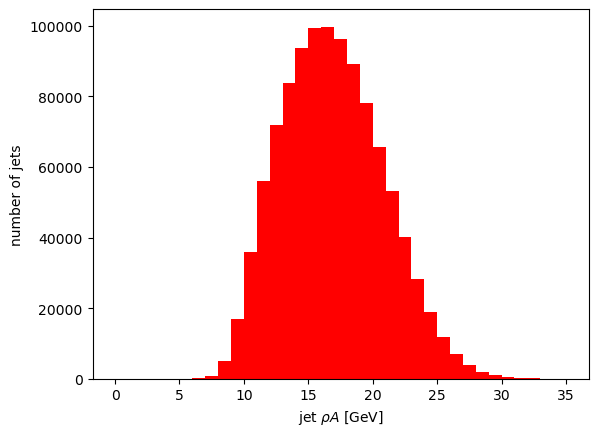

In [37]:
plt.hist(df_embed['rho']*df_embed['jet_area'], bins=np.arange(0,36),color='r')
plt.xlabel(r'jet $\rho A$ [GeV]')
plt.ylabel('number of jets')

In [38]:
df_embed_sub = applyCut(df_embed, 'jet_pt_sub > 15')

# Jet matching with $\Delta R(pythia, embed) < 0.4$

In [39]:
event_processed = 0
matched_data = []
unmatched_data = []
for runnumber in np.unique(df_pythia_evt['runnumber']):
    for eventnumber in np.unique(df_pythia_evt[df_pythia_evt.runnumber == runnumber]['eventnumber']):
        event_processed += 1
        if (event_processed % 1000 == 0):
            print('processing event', event_processed)
        subdf_embed = df_embed_sub[(df_embed_sub.runnumber == runnumber) & (df_embed_sub.eventnumber == eventnumber)]
        subdf_pythia = df_pythia[(df_pythia.runnumber == runnumber) & (df_pythia.eventnumber == eventnumber)]
        matched_i = []
        matched_j = []
        for i in range(0, subdf_embed.shape[0]): # loop over all embedded jets in the event
            if (i in matched_i):
                continue
            eta_embed = subdf_embed.iloc[i]['jet_eta']
            phi_embed = subdf_embed.iloc[i]['jet_phi']
            matched = False
            for j in range(0, subdf_pythia.shape[0]): # loop over all pythia jets in the event
                if (j in matched_j):
                    continue
                deta = eta_embed - subdf_pythia.iloc[j]['jet_eta']
                dphi = phi_embed - subdf_pythia.iloc[j]['jet_phi']
                dr = np.sqrt(deta*deta + dphi*dphi)
                if (dr < 0.4):
                    matched = True
                    matched_i.append(i)
                    matched_j.append(j)
                    matched_data.append([subdf_pythia.iloc[j]['centrality'], subdf_pythia.iloc[j]['jet_pt'],\
                    subdf_pythia.iloc[j]['jet_leading_track_pt'], subdf_pythia.iloc[j]['jet_leading_track_charge'], subdf_pythia.iloc[j]['jet_leading_track_y'], subdf_pythia.iloc[j]['jet_leading_track_phi'],\
                    subdf_pythia.iloc[j]['jet_subleading_track_pt'], subdf_pythia.iloc[j]['jet_subleading_track_charge'], subdf_pythia.iloc[j]['jet_subleading_track_y'], subdf_pythia.iloc[j]['jet_subleading_track_phi'],\
                    subdf_embed.iloc[i]['rho'], subdf_embed.iloc[i]['jet_pt'], subdf_embed.iloc[i]['jet_area'], subdf_embed.iloc[i]['jet_pt_sub'],\
                    subdf_embed.iloc[i]['jet_leading_track_pt'],subdf_embed.iloc[i]['jet_leading_track_charge'],subdf_embed.iloc[i]['jet_leading_track_y'],subdf_embed.iloc[i]['jet_leading_track_phi'],\
                    subdf_embed.iloc[i]['jet_subleading_track_pt'],subdf_embed.iloc[i]['jet_subleading_track_charge'],subdf_embed.iloc[i]['jet_subleading_track_y'],subdf_embed.iloc[i]['jet_subleading_track_phi'],\
                    dr, subdf_embed.iloc[i]['jet_pt_sub']-subdf_pythia.iloc[j]['jet_pt'], subdf_pythia.iloc[j]['w']])
                    break
            if (matched == False):
                unmatched_data.append(subdf_embed.iloc[i])

processing event 1000
processing event 2000
processing event 3000
processing event 4000
processing event 5000
processing event 6000
processing event 7000
processing event 8000
processing event 9000
processing event 10000
processing event 11000
processing event 12000
processing event 13000
processing event 14000
processing event 15000
processing event 16000
processing event 17000
processing event 18000
processing event 19000
processing event 20000
processing event 21000
processing event 22000
processing event 23000
processing event 24000
processing event 25000
processing event 26000
processing event 27000
processing event 28000
processing event 29000
processing event 30000
processing event 31000
processing event 32000
processing event 33000
processing event 34000
processing event 35000
processing event 36000
processing event 37000
processing event 38000
processing event 39000
processing event 40000
processing event 41000
processing event 42000
processing event 43000
processing event 440

In [40]:
df_matched = pd.DataFrame(matched_data, columns=['centrality','jet_pt',\
                        'jet_leading_track_pt','jet_leading_track_charge', 'jet_leading_track_y', 'jet_leading_track_phi',\
                        'jet_subleading_track_pt','jet_subleading_track_charge','jet_subleading_track_y','jet_subleading_track_phi',\
                        'embed_rho','embed_jet_pt','embed_jet_area','embed_jet_pt_sub',\
                        'embed_jet_leading_track_pt','embed_jet_leading_track_charge','embed_jet_leading_track_y','embed_jet_leading_track_phi',\
                        'embed_jet_subleading_track_pt','embed_jet_subleading_track_charge','embed_jet_subleading_track_y','embed_jet_subleading_track_phi',\
                        'dr', 'dpt', 'w'])
df_unmatched = pd.DataFrame(unmatched_data)

In [41]:
df_matched.eval('b_ch = embed_jet_leading_track_charge * embed_jet_subleading_track_charge', inplace=True)

In [42]:
df_matched_array = [ df_matched[(df_matched.embed_jet_pt_sub>20) & (df_matched.embed_jet_pt_sub<25)],\
                    df_matched[(df_matched.embed_jet_pt_sub>25) & (df_matched.embed_jet_pt_sub<30)],\
                    df_matched[(df_matched.embed_jet_pt_sub>30) & (df_matched.embed_jet_pt_sub<40)] ]

In [43]:
rc_matched_array = []
rc_err_matched_array = []
for i in range(0, len(df_matched_array)):
    rc_matched_array.append(getRcAndErr(df_matched_array[i], 'b_ch')[0])
    rc_err_matched_array.append(getRcAndErr(df_matched_array[i], 'b_ch')[1])

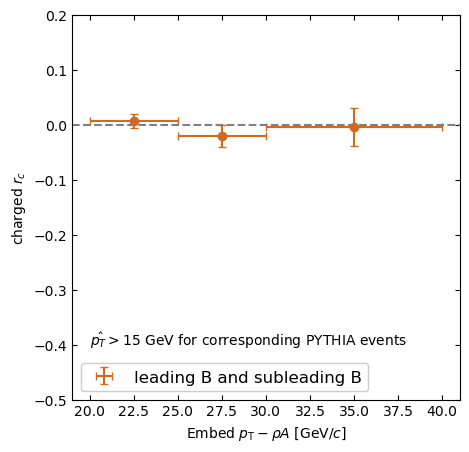

In [49]:
fig=plt.figure(figsize=(5,5))
plt.errorbar([22.5, 27.5, 35], rc_matched_array, ls='none', marker='o', color='chocolate')
plt.errorbar([22.5, 27.5, 35], rc_matched_array, xerr=[2.5, 2.5, 5], yerr=rc_err_matched_array, capsize=3, ls='none', label='leading B and subleading B', color='chocolate')
plt.axhline(y=0.0, color='grey', linestyle='--')
plt.text(20,-0.4,r'$\hat{p_T}>15$ GeV for corresponding PYTHIA events')
plt.xlabel(r'Embed $p_{\mathrm{T}}-\rho A$ [GeV$/c$]')
plt.ylabel('charged $r_c$')
plt.ylim(-0.5,0.2)
plt.legend(fontsize=12, loc='lower left', frameon=True, framealpha=1)
ax = plt.gca()
ax.tick_params(top=True, right=True, bottom=True, left=True, direction='in', which='both')

In [50]:
print(rc_matched_array)
print(rc_err_matched_array)

[0.006893634305183383, -0.021241793477839756, -0.003739747686019121]
[0.01310271259402139, 0.0203884097533534, 0.0344492134334599]


In [30]:
df_matched['w'] = np.ones(df_matched.shape[0]) # don't weigh by pythia event cross section

In [31]:
df_matched_array = [ df_matched[(df_matched.embed_jet_pt_sub>20) & (df_matched.embed_jet_pt_sub<25)],\
                    df_matched[(df_matched.embed_jet_pt_sub>25) & (df_matched.embed_jet_pt_sub<30)],\
                    df_matched[(df_matched.embed_jet_pt_sub>30) & (df_matched.embed_jet_pt_sub<40)] ]

In [32]:
rc_matched_array = []
rc_err_matched_array = []
for i in range(0, len(df_matched_array)):
    rc_matched_array.append(getRcAndErr(df_matched_array[i], 'b_ch')[0])
    rc_err_matched_array.append(getRcAndErr(df_matched_array[i], 'b_ch')[1])

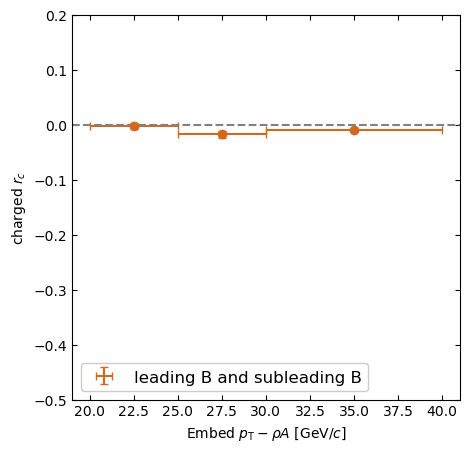

In [33]:
fig=plt.figure(figsize=(5,5))
plt.errorbar([22.5, 27.5, 35], rc_matched_array, ls='none', marker='o', color='chocolate')
plt.errorbar([22.5, 27.5, 35], rc_matched_array, xerr=[2.5, 2.5, 5], yerr=rc_err_matched_array, capsize=3, ls='none', label='leading B and subleading B', color='chocolate')
plt.axhline(y=0.0, color='grey', linestyle='--')
plt.xlabel(r'Embed $p_{\mathrm{T}}-\rho A$ [GeV$/c$]')
plt.ylabel('charged $r_c$')
plt.ylim(-0.5,0.2)
plt.legend(fontsize=12, loc='lower left', frameon=True, framealpha=1)
ax = plt.gca()
ax.tick_params(top=True, right=True, bottom=True, left=True, direction='in', which='both')

In [35]:
print(rc_matched_array)
print(rc_err_matched_array)

[-0.0028411694620108147, -0.017982017982017984, -0.009981736885194282]
[0.00552720206435342, 0.005586473532840939, 0.003967681416986654]
